<a href="https://colab.research.google.com/github/ThuyLienNguyen/FSVRG-ADMM/blob/master/FSVRG_dc_advantage.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# A genuine DC example where fixed FSVRG uses less gradient work

**CPU runtime; Run all.** All data and all six algorithms are included in this
notebook. No data upload, Google Drive mount, GPU, or external Python file is
needed. The setup cell installs dependencies only if needed.

## Nonconvex model

$$\min_{x=y}\frac{\|Dx-b\|^2}{2n}
 +\lambda\sum_{j=1}^d\min\{|y_j|,\tau\}+\frac\mu2\|y\|^2,$$

with $n=1024$, $d=24$, $\lambda=10^{-3}$, $\mu=10^{-5}$, $\tau=0.5$.
The Gaussian design has a dense correlation structure with population
covariance eigenvalues ranging from 1 to $10^{-3}$. The coefficient vector is
dense Gaussian, with Gaussian observation noise of standard deviation $10^{-3}$.

The explicit difference-of-convex decomposition is

$$g(y)=\lambda\|y\|_1+\frac\mu2\|y\|^2,
\qquad h(y)=\lambda\sum_j(|y_j|-\tau)_+.$$

Both $g$ and $h$ are convex, and $h$ is nonzero along the terminating
trajectories. The capped penalty's derivative jumps downward at $\pm\tau$,
so the full objective is genuinely nonconvex even though its loss is quadratic.
The ridge term makes the regularizer coercive.

## Common accuracy target

Define the feasible objective $F(y)=f(y)+g(y)-h(y)$. Every method must satisfy

$$\frac{\operatorname{dist}(0,\partial_L F(y))}
 {\max\{1,\|\nabla f(0)\|\}}\le10^{-5},\qquad
\frac{\|x-y\|}{\max\{1,\|x\|,\|y\|\}}\le10^{-5}.$$

$\partial_L$ is the limiting subdifferential. At the downward cap kink it
has two endpoint slopes, not their entire interval; the code implements this
distinction. No numerical snapping to zero or to a cap is used. The common
residual and the reported objective are both evaluated at the same feasible
candidate $(y,y)$. A small residual does not certify a global minimum.

## Measured full-run results

The local validation run used five fresh datasets, seeds 2001--2005, and
sampling seeds 41, 43, 47. These are five independent datasets with three
sampling runs each. The deterministic comparators repeat their trajectories
across the three sampling seeds. All settings were frozen using pilot data111
and sampling7 before these tests.

| Method | Successes | Median optimizer gradient passes |
|---|---:|---:|
| **FSVRG-ADMM (fixed relaxation)** | **15/15** | **98.5** |
| Nonconvex SVRG-ADMM | 15/15 | 217.5 |
| Proximal DCA | 15/15 | 4232 |
| SVRG-DC ablation | 15/15 | 250.5 |
| Full-gradient DC ablation | 12/15 | 2016 |
| AFSVRG-ADMM (adaptive relaxation) | 14/15 | 118.5 |

Medians are over successful runs. Full-gradient DC failed numerically on
dataset2005 for all three repeated sampling labels. AFSVRG exhausted the
8000-pass budget on data2004/sampling41. **Both outcomes are retained.**
FSVRG used less work in every paired run against each of the three fully
successful comparators. Its median paired work ratios were 2.21 against
nonconvex SVRG, 43.21 against pDCA, and 2.79 against the SVRG-DC ablation.

The attained local minima can differ. Relative to the best successful
comparator in each pair, FSVRG's final objective ranged from about 0.62% lower
to 1.18% higher. This is a stationarity-speed advantage, not a claim of
uniformly better objectives. The fixed setting $\alpha=1/2$ isolates gradient
momentum; the adaptive variant did not improve this benchmark overall.

## Work and implementation conventions

One optimizer gradient pass is $n$ component-gradient evaluations. Snapshots
cost $n$ and each mini-batch SVRG difference costs $2b$, with $b=32$. All
stochastic methods use the same with-replacement sampling convention and the
same quadratic gradient-difference shortcut. Every optimizer gradient is
computed from the data matrix. Cached Gram diagnostics and their setup are
separate from the optimizer count and timer; monitor time is saved separately.
The Gram matrix also supplies pDCA's Lipschitz step bound. Using cached Gram
gradients could accelerate the optimizers too; this is the stated finite-sum
implementation comparison, not a fastest quadratic-solver claim.

The example family was chosen through pilot exploration. The final searches
contain192 configurations for each manuscript family,126 for nonconvex SVRG,
and6 pDCA step factors. Raw tuning records are in the companion bundle.
The parameter search is finite, and the empirical settings are not claimed
to satisfy every sufficient inequality in the manuscript's theorem.

## External comparator sources

- Huang, Chen and Lu (2017), [arXiv:1610.02758v5, Algorithm2](https://arxiv.org/pdf/1610.02758).
  The implementation uses mini-batches and last-iterate monitoring in place
  of the source's single-sample estimator and randomized theoretical output.
  Its nonconvex penalty subproblem is solved globally coordinatewise.
- Wen, Chen and Pong, [Proximal DCA, equation(3.3)](https://ira.lib.polyu.edu.hk/bitstream/10397/79655/1/a0585-n03_pDCAe_v2_new.pdf),
  equivalently pDCAe with zero extrapolation, using step $1/L_f$ on each dataset.

The two manuscript ablations are labeled separately from these external
comparators. The post-run local-region reference checks are diagnostics only,
never optimizer updates or global-optimality certificates.


## 1. Dependencies


In [ ]:
import importlib.metadata
import re
import subprocess
import sys

minimum_versions={"numpy":(1,23),"pandas":(1,5),"matplotlib":(3,7),"threadpoolctl":(3,1)}
needed=[]
for package,minimum in minimum_versions.items():
    try:
        installed=tuple(map(int,re.findall(r"\d+",importlib.metadata.version(package))[:2]))
        if installed<minimum:
            needed.append(f"{package}>={minimum[0]}.{minimum[1]}")
    except importlib.metadata.PackageNotFoundError:
        needed.append(f"{package}>={minimum[0]}.{minimum[1]}")
if needed:
    subprocess.check_call([sys.executable,"-m","pip","install","-q",*needed])
print("Dependencies ready:",{p:importlib.metadata.version(p) for p in minimum_versions})


Dependencies ready: {'numpy': '2.1.3', 'pandas': '2.2.3', 'matplotlib': '3.10.0', 'threadpoolctl': '3.7.0'}


## 2. Complete implementations and mathematical checks


In [ ]:
"""Genuine nonconvex DC benchmark: capped-l1 regularized least squares.

Self-contained CPU code for Google Colab; run the companion notebook or:
    %run fsvrg_dc_advantage.py --mode full --show
    %run fsvrg_dc_advantage.py --mode quick --show

Model: min_{x=y} ||D x-b||^2/(2n) + lambda*sum min(|y|,tau)
       + mu*||y||^2/2.
g(y)=lambda||y||_1+mu||y||^2/2, h(y)=lambda sum (|y|-tau)_+.
Proposed specialization: A=I, B=-I, c=0, theta=eta=1.

The stopping test uses the EXACT original limiting-subgradient distance at
(y,y), including the TWO endpoint slopes at the downward cap kink, together
with consensus feasibility. It is not merely a lifted DC criticality test.
No global optimality is claimed. The direct active-region solve is a POST-RUN
local reference only and never changes an optimizer's iterate.

Published comparators:
Huang, Chen and Lu, arXiv:1610.02758v5 (2017), Algorithm 2:
https://arxiv.org/pdf/1610.02758
Our NC-SVRG implementation uses minibatches and last-iterate diagnostics in
place of the source's single-sample estimator and randomized theoretical output.
Wen, Chen and Pong, Computational Optimization and Applications 69 (2018):
https://ira.lib.polyu.edu.hk/bitstream/10397/79655/1/a0585-n03_pDCAe_v2_new.pdf
Proximal DCA is equation(3.3), equivalently pDCAe with zero extrapolation.
The other baseline methods are explicitly labeled manuscript ablations.

Every optimizer gradient is evaluated from D, never from the Gram matrix.
H=D.T@D/n is used for cheap COMMON diagnostics, local-reference checks, and
the pDCA Lipschitz step-size bound. Its setup is excluded from solver timing.
Logical optimizer gradient cost is n per full gradient and 2*batch per SVRG
update, including all snapshot costs. Quadratic SVRG differences are fused
uniformly in all stochastic implementations. Monitoring and plotting are
excluded from the optimizer count/timer and monitor time is saved separately.

The problem family and parameters were selected on pilot data111 and
sampling7 only. Final test data2001..2005 and sampling41,43,47 were reserved
until parameters were frozen. Finite-grid tuning is not global optimization
of hyperparameters, and these empirical settings are not certified to meet
all sufficient inequalities in the manuscript's convergence theorem.
"""
from __future__ import annotations
import argparse
import json
import platform
from contextlib import nullcontext
import matplotlib.pyplot as plt
try:
    from threadpoolctl import threadpool_limits
except ImportError:
    threadpool_limits=None

from dataclasses import dataclass, asdict
from pathlib import Path
import time
import numpy as np
import pandas as pd


def soft(u, threshold):
    return np.sign(u) * np.maximum(np.abs(u) - threshold, 0.)


def make_problem(seed=111, n=1024, d=24, lam=1e-3, mu=1e-5, tau=.5):
    rng = np.random.default_rng(seed)
    U, _ = np.linalg.qr(rng.normal(size=(d, d)))
    C = np.sqrt(np.geomspace(1., 1e-3, d))[:, None] * U.T
    D = rng.normal(size=(n, d)) @ C
    D_test = rng.normal(size=(256, d)) @ C
    truth = rng.normal(size=d)
    b = D @ truth + .001 * rng.normal(size=n)
    b_test = D_test @ truth + .001 * rng.normal(size=256)
    H = D.T @ D / n
    rhs = D.T @ b / n
    return dict(D=D, b=b, D_test=D_test, b_test=b_test, truth=truth,
                H=H, rhs=rhs, constant=.5*np.mean(b*b), lam=lam, mu=mu,
                tau=tau, n=n, d=d, seed=int(seed),
                scale=max(1., np.linalg.norm(rhs)), L=float(np.linalg.eigvalsh(H)[-1]))


def gradient(p, x):
    return p['D'].T @ (p['D'] @ x-p['b'])/p['n']


def prox_capped(u, rho, lam, mu, tau):
    """Global minimizer of penalty(y) + rho/2 ||y-u||^2, coordinatewise."""
    a = np.abs(rho*u)
    q = rho+mu
    low = np.minimum(np.maximum(a-lam, 0.)/q, tau)
    high = np.maximum(a/q, tau)
    val_low = .5*q*low**2-a*low+lam*low
    val_high = .5*q*high**2-a*high+lam*tau
    return np.sign(u)*np.where(val_low <= val_high, low, high)


def stationarity_vector(p, y, smooth_gradient=None):
    """Minimum-norm limiting subgradient of the feasible original objective.

    At the downward cap kink, use TWO ENDPOINTS, never their convex hull.
    Exact comparisons deliberately avoid silently snapping near-kink points.
    """
    a = p['H'] @ y-p['rhs'] if smooth_gradient is None else smooth_gradient.copy()
    a = a+p['mu']*y
    lam, tau = p['lam'], p['tau']
    size = np.abs(y)
    sign = np.sign(y)
    result = a.copy()
    zero = size == 0.
    interior = (size > 0.) & (size < tau)
    kink = size == tau
    result[zero] = soft(a[zero], lam)
    result[interior] += lam*sign[interior]
    other = a[kink]+lam*sign[kink]
    result[kink] = np.where(np.abs(a[kink]) <= np.abs(other), a[kink], other)
    return result


def diagnostics(p, x, y, w, nu):
    residual = stationarity_vector(p, y)
    feasibility = np.linalg.norm(x-y)/max(1., np.linalg.norm(x), np.linalg.norm(y))
    loss = .5*y @ p['H'] @ y-p['rhs'] @ y+p['constant']
    penalty = p['lam']*np.minimum(np.abs(y),p['tau']).sum()+.5*p['mu']*(y@y)
    rx = p['H'] @ x-p['rhs']-nu
    ry = y-soft(y+w-nu,p['lam'])/(1+p['mu'])
    rw = w-np.clip(soft(w+y,p['tau']),-p['lam'],p['lam'])
    lifted = np.sqrt(rx@rx+ry@ry+rw@rw+np.sum((x-y)**2))/p['scale']
    return dict(stationarity=float(np.linalg.norm(residual)/p['scale']),
                feasibility=float(feasibility), objective=float(loss+penalty),
                lifted_kkt=float(lifted), h_value=float(p['lam']*np.maximum(np.abs(y)-p['tau'],0.).sum()),
                capped_coordinates=int(np.sum(np.abs(y)>p['tau'])),
                zero_coordinates=int(np.sum(y==0.)),
                minimum_cap_margin=float(np.min(np.abs(np.abs(y)-p['tau']))))


@dataclass(frozen=True)
class Config:
    name: str
    family: str = 'ours'  # ours, full, nc_svrg, pdca
    rho: float = .1
    qz: float = .3
    qy: float = .01
    beta: float = .15
    alpha: float | str = .5
    m: int = 32
    step_factor: float = 1.


def solve(p, cfg, sampling_seed=7, batch=32, max_passes=5000, tolerance=1e-5,
          diagnostic_every=8, stop_on_tolerance=True):
    x=np.zeros(p['d']); y=x.copy(); w=x.copy(); nu=x.copy()
    snapshot=x.copy(); full_snapshot=None; momentum=None
    rng=np.random.default_rng(sampling_seed)
    calls=iterations=0
    solver_seconds=0.
    monitor_seconds=0.
    history=[]
    status='budget_exhausted'
    violation_max=0.
    first_hit=None

    def record():
        nonlocal monitor_seconds,first_hit
        begin=time.perf_counter()
        row=diagnostics(p,x,y,w,nu)
        monitor_seconds+=time.perf_counter()-begin
        row.update(method=cfg.name,data_seed=p['seed'],sampling_seed=sampling_seed,
                   iterations=iterations,gradient_evaluations=calls,passes=calls/p['n'],
                   solver_seconds=solver_seconds,monitor_seconds=monitor_seconds)
        history.append(row)
        hit=row['stationarity']<=tolerance and row['feasibility']<=tolerance
        if hit and first_hit is None:
            first_hit=row.copy()
        return hit

    if record() and stop_on_tolerance:
        status='converged'
    budget=int(max_passes*p['n'])
    while calls < budget and status!='converged':
        stochastic=cfg.family in ('ours','nc_svrg')
        refresh=stochastic and iterations % cfg.m==0
        cost=(p['n'] if refresh else 0)+(2*batch if stochastic else p['n'])
        if calls+cost > budget:
            break
        begin=time.perf_counter()
        if refresh:
            snapshot=x.copy()
            full_snapshot=gradient(p,snapshot)
            calls+=p['n']
            if momentum is None:
                momentum=full_snapshot.copy()
        if stochastic:
            ids=rng.integers(0,p['n'],size=batch)
            Db=p['D'][ids]
            raw=Db.T @ (Db @ (x-snapshot))/batch+full_snapshot
            calls+=2*batch
        else:
            raw=gradient(p,x)
            calls+=p['n']
        if cfg.family=='pdca':
            sub_h=p['lam']*np.sign(x)*(np.abs(x)>p['tau'])
            step=cfg.step_factor/p['L']
            x=soft(x-step*(raw-sub_h),step*p['lam'])/(1+step*p['mu'])
            y=x.copy()
            w=p['lam']*np.sign(y)*(np.abs(y)>p['tau'])
            # Multipliers are irrelevant for a feasible one-variable method.
            nu=np.zeros_like(y)
        elif cfg.family=='nc_svrg':
            y_new=prox_capped(x-nu/cfg.rho,cfg.rho,p['lam'],p['mu'],p['tau'])
            x_new=(cfg.qz*x-raw+cfg.rho*y_new+nu)/(cfg.rho+cfg.qz)
            nu=nu-cfg.rho*(x_new-y_new)
            x,y=x_new,y_new
            w=p['lam']*np.sign(y)*(np.abs(y)>p['tau'])
        else:
            if cfg.family=='full':
                momentum=raw
            else:
                momentum=(1-cfg.beta)*momentum+cfg.beta*raw
            y_new=soft(cfg.rho*x-nu+w+cfg.qy*y,p['lam'])/(cfg.rho+cfg.qy+p['mu'])
            old_residual=x-y_new
            x_half=(-momentum+nu+cfg.rho*y_new+cfg.qz*x)/(cfg.rho+cfg.qz)
            if cfg.alpha=='adaptive':
                direction=2*cfg.rho*old_residual/(cfg.rho+cfg.qz)
                squared=float(direction@direction)
                offset=float((x_half-y_new)@direction/squared) if squared>0 else 0.
                alpha=.5+float(np.clip(offset,-.4,.4))
            else:
                alpha=float(cfg.alpha)
            x_new=x_half-cfg.rho*(2*alpha-1)*old_residual/(cfg.rho+cfg.qz)
            w=np.clip(soft(w+y_new,p['tau']),-p['lam'],p['lam'])
            nu=nu-cfg.rho*(x_new-y_new)-cfg.rho*(2*alpha-1)*old_residual
            if cfg.alpha=='adaptive':
                violation=np.linalg.norm(x_new-y_new)-np.linalg.norm(x_half-y_new)
                violation_max=max(violation_max,float(violation))
                if violation > 1e-10*(1+np.linalg.norm(x_half-y_new)):
                    raise AssertionError('Adaptive same-state residual property failed.')
            x,y=x_new,y_new
        iterations+=1
        finite=all(np.all(np.isfinite(a)) for a in (x,y,w,nu)) and np.linalg.norm(x)<1e10
        solver_seconds+=time.perf_counter()-begin
        if not finite:
            status='numerical_failure'
            break
        if iterations % diagnostic_every==0 and record() and stop_on_tolerance:
            status='converged'
            break
    if status!='numerical_failure' and history[-1]['iterations']!=iterations:
        if record():
            status='converged'
    result=history[-1].copy()
    if status=='numerical_failure':
        for key in ['stationarity','feasibility','objective','lifted_kkt','h_value','minimum_cap_margin',
                    'capped_coordinates','zero_coordinates']:
            result[key]=np.nan
        result.update(iterations=iterations,gradient_evaluations=calls,passes=calls/p['n'],solver_seconds=solver_seconds)
        history.append(result.copy())
    result.update(status=status,reached_tolerance=first_hit is not None,
                  passes_to_tolerance=first_hit['passes'] if first_hit else np.nan,
                  time_to_tolerance=first_hit['solver_seconds'] if first_hit else np.nan,
                  adaptive_max_violation=violation_max)
    if cfg.family=='pdca':
        result['lifted_kkt']=np.nan
        for row in history:
            row['lifted_kkt']=np.nan
    return pd.DataFrame(history),result,dict(x=x,y=y,w=w,nu=nu)


# Frozen on pilot data111/sampling7, before evaluating the test seeds below.
CONFIGS = [
    Config('Nonconvex SVRG-ADMM', 'nc_svrg', rho=.1, qz=.6, qy=0., beta=1., m=128),
    Config('Proximal DCA', 'pdca', beta=1., step_factor=1.),
    Config('SVRG-DC ablation', 'ours', rho=.3, qz=.3, qy=.001, beta=1., alpha=.5),
    Config('Full-gradient DC ablation', 'full', rho=.3, qz=.3, qy=.001, beta=1., alpha=.9),
    Config('FSVRG-ADMM (ours)', 'ours', rho=.1, qz=.1, qy=.01, beta=.15, alpha=.5),
    Config('AFSVRG-ADMM (ours)', 'ours', rho=.01, qz=.3, qy=.001, beta=.15, alpha='adaptive'),
]
TEST_DATA_SEEDS = [2001, 2002, 2003, 2004, 2005]
TEST_SAMPLING_SEEDS = [41, 43, 47]


def local_reference(p, y):
    """Post-run check of the stationary point in y's fixed active region.

    This verifies a local region only. It never proves global optimality,
    changes a trajectory, or enters the stopping rule.
    """
    nonzero = y != 0.
    capped = np.abs(y) > p['tau']
    small = nonzero & ~capped
    Q = p['H'] + p['mu']*np.eye(p['d'])
    point = np.zeros_like(y)
    linear = p['lam']*np.sign(y)*small
    point[nonzero] = np.linalg.solve(Q[np.ix_(nonzero, nonzero)],
                                    (p['rhs']-linear)[nonzero])
    residual = Q @ point-p['rhs']
    inactive_margin = p['lam']-np.max(np.abs(residual[~nonzero]), initial=0.)
    cap_margin = float(np.min(np.abs(np.abs(point)-p['tau'])))
    valid = (np.array_equal(np.sign(point[nonzero]),np.sign(y[nonzero]))
             and np.array_equal(np.abs(point)>p['tau'], capped)
             and inactive_margin > 1e-10 and cap_margin > 1e-10)
    signature = ''.join('0' if a == 0 else ('P' if a > 0 else 'N') if abs(a) > p['tau']
                        else ('p' if a > 0 else 'n') for a in point)
    loss = .5*point @ p['H'] @ point-p['rhs'] @ point+p['constant']
    penalty = p['lam']*np.minimum(np.abs(point),p['tau']).sum()+.5*p['mu']*(point@point)
    return dict(valid_local_region=bool(valid), local_reference_objective=float(loss+penalty),
                local_reference_stationarity=float(np.linalg.norm(stationarity_vector(p,point))/p['scale']),
                reference_loss=float(loss), reference_penalty=float(penalty),
                inactive_margin=float(inactive_margin), reference_cap_margin=cap_margin,
                region_signature=signature, local_reference_point=point.tolist())


def validation_checks():
    """Independent checks of the consequential mathematical operations."""
    p=make_problem(111)
    rng=np.random.default_rng(371)
    x=rng.normal(size=p['d']); direction=rng.normal(size=p['d'])
    direction/=np.linalg.norm(direction)
    f=lambda a: .5*np.mean((p['D']@a-p['b'])**2)
    eps=1e-6
    np.testing.assert_allclose((f(x+eps*direction)-f(x-eps*direction))/(2*eps),
                               gradient(p,x)@direction,rtol=1e-6,atol=1e-8)
    np.testing.assert_allclose(p['H']@x-p['rhs'],gradient(p,x),atol=5e-14)
    ids=rng.integers(0,p['n'],size=32); Db=p['D'][ids]; bb=p['b'][ids]
    snap=rng.normal(size=p['d'])
    direct=Db.T@(Db@x-bb)/32-Db.T@(Db@snap-bb)/32
    np.testing.assert_allclose(direct,Db.T@(Db@(x-snap))/32,atol=5e-14)
    # Moreau identity for h: the independent primal prox has three branches.
    for step in [.1,1.,10.]:
        u=rng.normal(size=100)
        z=u/step; t=1/step; size=np.abs(z)
        primal=np.sign(z)*np.where(size<=p['tau'],size,
                  np.where(size<=p['tau']+t*p['lam'],p['tau'],size-t*p['lam']))
        conjugate=np.clip(soft(u,step*p['tau']),-p['lam'],p['lam'])
        np.testing.assert_allclose(conjugate,u-step*primal,atol=3e-14)
    # Independent grid check of the global nonconvex prox, including cap points.
    grid=np.unique(np.r_[np.linspace(-2,2,10001),-p['tau'],0,p['tau']])
    for rho in [.01,.1,1.]:
        for u in [-1.2,-.501,-.499,-.001,0.,.001,.499,.501,1.2]:
            value=lambda a: .5*rho*(a-u)**2+p['lam']*np.minimum(np.abs(a),p['tau'])+.5*p['mu']*a*a
            prox=prox_capped(np.array([u]),rho,p['lam'],p['mu'],p['tau'])[0]
            assert value(prox)<=np.min(value(grid))+1e-12
    # At a downward cap kink, DC/Clarke cancellation must NOT give zero.
    one=dict(H=np.ones((1,1)),rhs=np.array([.65]),lam=.2,mu=.1,tau=.5)
    np.testing.assert_allclose(np.abs(stationarity_vector(one,np.array([.5]))),[.1],atol=1e-14)
    # Independent random y-subproblem first-order conditions.
    x,y,w,nu=rng.normal(size=(4,p['d']))
    rho,qy=.3,.01
    yn=soft(rho*x-nu+w+qy*y,p['lam'])/(rho+qy+p['mu'])
    smooth=p['mu']*yn-w+nu+rho*(yn-x)+qy*(yn-y)
    active=yn!=0
    np.testing.assert_allclose(smooth[active]+p['lam']*np.sign(yn[active]),0.,atol=2e-14)
    assert np.all(np.abs(smooth[~active])<=p['lam']+2e-14)
    return 'Gradient, SVRG, conjugate prox, global capped prox, cap-kink and primal checks passed.'


def plot_results(history, results, outdir, show=False):
    colors=['#7c8591','#a66f9a','#bd9855','#7b6a59','#166bb1','#07966f']
    short=['NC-SVRG','pDCA','SVRG-DC','Full DC','FSVRG','AFSVRG']
    fig,axes=plt.subplots(2,2,figsize=(12,8),constrained_layout=True)
    ds,ss=int(results.data_seed.min()),int(results.sampling_seed.min())
    representative=history[(history.data_seed==ds)&(history.sampling_seed==ss)]
    for cfg,color in zip(CONFIGS,colors):
        trace=representative[(representative.method==cfg.name)&(representative.passes>0)]
        axes[0,0].loglog(trace.passes,np.maximum(trace.stationarity,1e-16),color=color,lw=2,label=cfg.name)
        axes[0,1].loglog(trace.passes,np.maximum(trace.objective,1e-16),color=color,lw=2)
    axes[0,0].axhline(1e-5,color='#777777',ls=':',lw=1)
    axes[0,0].set_ylabel('Relative original stationarity at y')
    axes[0,0].set_title(f'Trajectory: data {ds}, sampling {ss}')
    axes[0,1].set_ylabel('Feasible nonconvex objective F(y)')
    axes[0,1].set_title('Objective values along the same trajectories')
    for ax in axes[0]:
        ax.set_xlabel('Optimizer component-gradient evaluations / n')
        ax.grid(True,alpha=.18)
    for ax,metric,label in [
        (axes[1,0],'passes_to_tolerance','Optimizer gradient passes to joint tolerance'),
        (axes[1,1],'time_to_tolerance','Solver seconds to joint tolerance')]:
        for j,(cfg,color) in enumerate(zip(CONFIGS,colors)):
            series=results.loc[results.method==cfg.name,metric]
            values=series[np.isfinite(series)].to_numpy()
            if len(values):
                q1,median,q3=np.quantile(values,[.25,.5,.75])
                ax.bar(j,median,color=color,alpha=.85,width=.7)
                ax.errorbar(j,median,yerr=np.array([[median-q1],[q3-median]]),fmt='none',capsize=4,ecolor='#333333')
                ax.scatter(j+np.linspace(-.17,.17,len(values)),values,s=12,color='#333333',alpha=.4)
                number=(f'{median:,.1f}'.rstrip('0').rstrip('.')
                        if metric=='passes_to_tolerance' else f'{median:.3g}')
                ax.text(j,median*1.12,number,ha='center',fontsize=9)
            failed=int(series.isna().sum())
            if failed:
                ax.text(j,.97,f'{failed} failed',transform=ax.get_xaxis_transform(),ha='center',va='top',color='#a62f2f')
        ax.set_xticks(range(len(CONFIGS)),short,rotation=20,ha='right')
        ax.set_yscale('log'); ax.set_ylabel(label)
        ax.set_title('Successful runs: median and spread')
        ax.grid(True,axis='y',alpha=.18)
    handles,labels=axes[0,0].get_legend_handles_labels()
    fig.legend(handles,labels,loc='outside lower center',ncol=3,frameon=False)
    fig.suptitle('Genuine DC regression: active capped-l1 regularization',fontsize=15)
    fig.savefig(outdir/'dc_comparison.png',dpi=180,bbox_inches='tight')
    fig.savefig(outdir/'dc_comparison.svg',bbox_inches='tight')
    if show: plt.show()
    else: plt.close(fig)


def benchmark(mode='full',output='fsvrg_dc_advantage_results',show=False):
    if mode not in ('quick','full'):
        raise ValueError('mode must be quick or full')
    print(validation_checks(),flush=True)
    data_seeds=TEST_DATA_SEEDS if mode=='full' else TEST_DATA_SEEDS[:1]
    sampling_seeds=TEST_SAMPLING_SEEDS if mode=='full' else TEST_SAMPLING_SEEDS[:1]
    outdir=Path(output); outdir.mkdir(parents=True,exist_ok=True)
    metadata=dict(n=1024,d=24,lam=.001,mu=.00001,tau=.5,population_condition=1000,
                  batch=32,diagnostic_every=8,max_passes=8000,tolerance=1e-5,
                  data_seeds=data_seeds,sampling_seeds=sampling_seeds,
                  pilot_data_seed=111,pilot_sampling_seed=7,
                  configs=[asdict(c) for c in CONFIGS],
                  primary_stop='original limiting stationarity at y and relative feasibility',
                  sampling='independent uniform indices with replacement; batch32',
                  work='optimizer gradient calls only: n per snapshot/full gradient,2b per difference',
                  monitor='cached Gram diagnostics; monitoring time separately recorded',
                  local_reference='post-run active-region stationary solve; not a global optimum',
                  timing='solver only; common setup, monitoring, local references and plotting excluded',
                  python_version=platform.python_version(),numpy_version=np.__version__,pandas_version=pd.__version__)
    # Written before the first test run, so frozen settings remain explicit.
    (outdir/'configuration.json').write_text(json.dumps(metadata,indent=2))
    rows=[]; histories=[]; states=[]
    for ds in data_seeds:
        p=make_problem(ds)
        print(f'\nDataset {ds}; initial gradient norm={np.linalg.norm(p["rhs"]):.4g}',flush=True)
        for ss in sampling_seeds:
            order=np.roll(np.arange(len(CONFIGS)),ss%len(CONFIGS))
            for j in order:
                cfg=CONFIGS[j]
                hist,result,state=solve(p,cfg,sampling_seed=ss,max_passes=8000)
                if result['status']!='numerical_failure':
                    ref=local_reference(p,state['y'])
                    point=ref.pop('local_reference_point')
                    result.update(ref)
                    result['gap_to_local_reference']=result['objective']-ref['local_reference_objective']
                else:
                    point=None
                histories.append(hist); rows.append(result)
                states.append(dict(method=cfg.name,data_seed=ds,sampling_seed=ss,
                                   x=state['x'].tolist(),y=state['y'].tolist(),
                                   local_reference_point=point))
                print(f'  {cfg.name:26s} seed={ss} passes={result["passes_to_tolerance"]:7.1f} '
                      f'R={result["stationarity"]:.2e} F={result["objective"]:.8f} {result["status"]}',flush=True)
    results=pd.DataFrame(rows); history=pd.concat(histories,ignore_index=True)
    summary=results.groupby('method',sort=False).agg(
        runs=('status','size'),successes=('reached_tolerance','sum'),
        median_passes=('passes_to_tolerance','median'),min_passes=('passes_to_tolerance','min'),
        max_passes=('passes_to_tolerance','max'),median_solver_seconds=('time_to_tolerance','median'),
        max_stationarity=('stationarity','max'),max_feasibility=('feasibility','max'),
        min_active_caps=('capped_coordinates','min'),max_active_caps=('capped_coordinates','max'),
        max_gap_to_local_reference=('gap_to_local_reference','max')
    ).reindex([c.name for c in CONFIGS]).reset_index()
    pivot=results.pivot(index=['data_seed','sampling_seed'],columns='method',values='passes_to_tolerance')
    paired=[]
    for ours in [c.name for c in CONFIGS[-2:]]:
        for baseline in [c.name for c in CONFIGS[:-2]]:
            both=pivot[[ours,baseline]].notna().all(axis=1)
            ratio=pivot.loc[both,baseline]/pivot.loc[both,ours]
            paired.append(dict(proposed=ours,baseline=baseline,pairs=len(pivot),
                               both_succeeded=int(both.sum()),
                               proposed_failures=int(pivot[ours].isna().sum()),
                               baseline_failures=int(pivot[baseline].isna().sum()),
                               strict_work_wins=int((ratio>1).sum()),ties=int((ratio==1).sum()),
                               median_paired_work_ratio=float(ratio.median()) if len(ratio) else np.nan))
    comparisons=pd.DataFrame(paired)
    objective_check=results[results.reached_tolerance].groupby('data_seed').agg(
        min_objective=('objective','min'),max_objective=('objective','max'),
        distinct_local_regions=('region_signature','nunique'),
        all_local_regions_valid=('valid_local_region','all'),
        min_local_reference=('local_reference_objective','min'),
        max_local_reference=('local_reference_objective','max'),
        min_h_value=('h_value','min'),max_h_value=('h_value','max'),
        min_cap_margin=('minimum_cap_margin','min'))
    objective_check['objective_spread']=objective_check.max_objective-objective_check.min_objective
    objective_check['unsuccessful_runs']=results.groupby('data_seed').reached_tolerance.apply(lambda a:int((~a).sum()))
    results.to_csv(outdir/'runs.csv',index=False)
    summary.to_csv(outdir/'summary.csv',index=False)
    history.to_csv(outdir/'trajectories.csv',index=False)
    comparisons.to_csv(outdir/'paired_comparisons.csv',index=False)
    objective_check.to_csv(outdir/'objective_checks.csv')
    (outdir/'final_states.json').write_text(json.dumps(states,indent=2))
    plot_results(history,results,outdir,show)
    print('\n'+summary.to_string(index=False))
    print('\n'+comparisons.to_string(index=False))
    print('\nObjective and local-region checks:\n'+objective_check.to_string())
    print('\nSaved results:',outdir.resolve())
    return results,summary,comparisons,objective_check


def main(argv=None):
    parser=argparse.ArgumentParser(description=__doc__)
    parser.add_argument('--mode',choices=['quick','full'],default='full')
    parser.add_argument('--output',default='fsvrg_dc_advantage_results')
    parser.add_argument('--show',action='store_true')
    args=parser.parse_args(argv)
    context=threadpool_limits(limits=1) if threadpool_limits else nullcontext()
    with context:
        benchmark(args.mode,args.output,args.show)


## 3. Run the benchmark


Gradient, SVRG, conjugate prox, global capped prox, cap-kink and primal checks passed.

Dataset 2001; initial gradient norm=1.176
  Proximal DCA               seed=41 passes= 4888.0 R=9.97e-06 F=0.01027221 converged
  SVRG-DC ablation           seed=41 passes=  298.5 R=8.42e-06 F=0.01027218 converged
  Full-gradient DC ablation  seed=41 passes= 2352.0 R=9.97e-06 F=0.01027221 converged
  FSVRG-ADMM (ours)          seed=41 passes=  105.0 R=9.99e-06 F=0.01022373 converged
  AFSVRG-ADMM (ours)         seed=41 passes=  154.5 R=8.98e-06 F=0.01020463 converged
  Nonconvex SVRG-ADMM        seed=41 passes=  271.5 R=7.50e-06 F=0.01027217 converged
  AFSVRG-ADMM (ours)         seed=43 passes=  145.5 R=8.95e-06 F=0.01027219 converged
  Nonconvex SVRG-ADMM        seed=43 passes=  263.0 R=8.25e-06 F=0.01027218 converged
  Proximal DCA               seed=43 passes= 4888.0 R=9.97e-06 F=0.01027221 converged
  SVRG-DC ablation           seed=43 passes=  304.5 R=9.45e-06 F=0.01027218 converged
  Full-gra

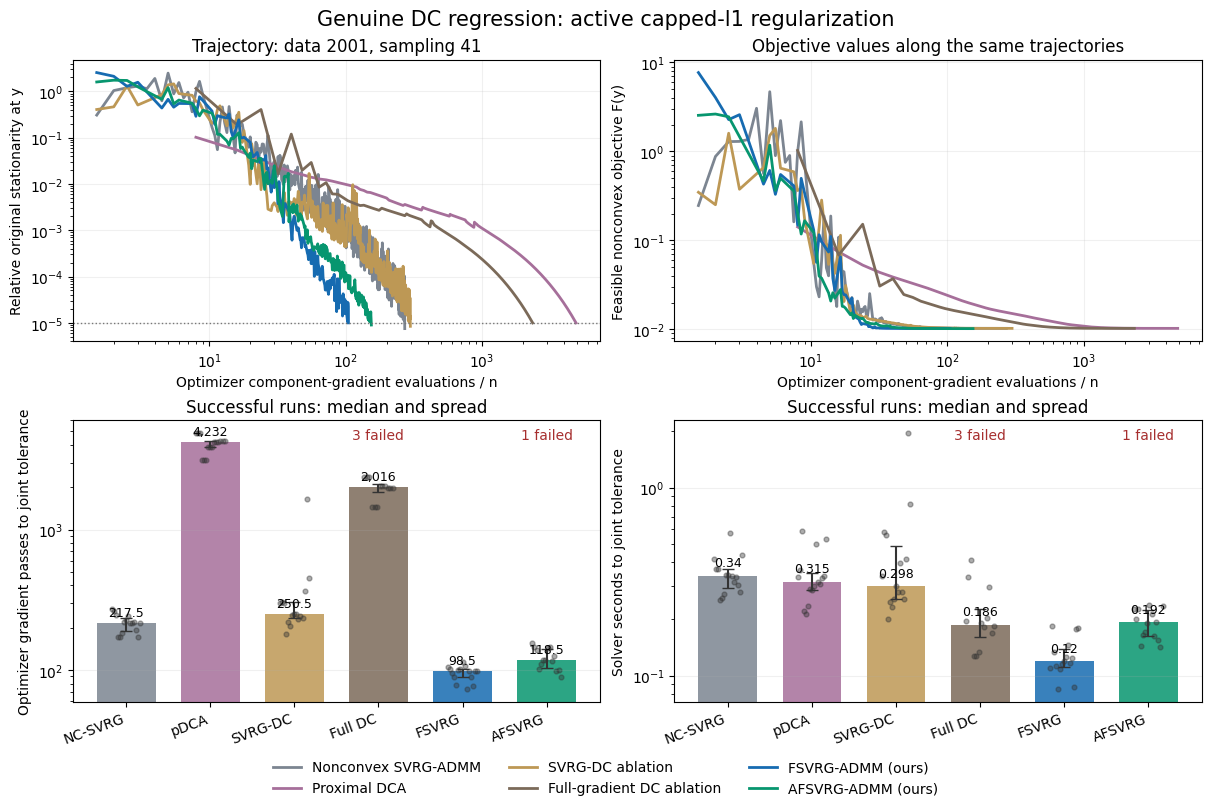


                   method  runs  successes  median_passes  min_passes  max_passes  median_solver_seconds  max_stationarity  max_feasibility  min_active_caps  max_active_caps  max_gap_to_local_reference
      Nonconvex SVRG-ADMM    15         15          217.5       172.5       271.5               0.339943          0.000010         0.000009             12.0             18.0                1.178949e-07
             Proximal DCA    15         15         4232.0      3112.0      4888.0               0.315408          0.000010         0.000000             12.0             18.0                1.394998e-07
         SVRG-DC ablation    15         15          250.5       181.5      1660.5               0.298178          0.000010         0.000008             12.0             18.0                1.150355e-07
Full-gradient DC ablation    15         12         2016.0      1456.0      2352.0               0.186375          0.000010         0.000003             12.0             18.0                1.

In [ ]:
# Full: all90 method/dataset/sampling combinations, including retained failures.
# Quick: the first data/sampling pair, with all six methods.
MODE="full"
OUTPUT_DIR="fsvrg_dc_advantage_results"
SHOW_PLOTS=True

context=threadpool_limits(limits=1) if threadpool_limits else nullcontext()
with context:
    results,summary,paired_comparisons,objective_checks=benchmark(
        mode=MODE,output=OUTPUT_DIR,show=SHOW_PLOTS
    )


## 4. Work, success counts, and retained failures


In [ ]:
try:
    from IPython.display import display
except ImportError:
    display=print
display(summary)
display(paired_comparisons)
display(objective_checks)
unsuccessful=results[~results.reached_tolerance]
print("Runs that did not reach the joint target:")
display(unsuccessful[["method","data_seed","sampling_seed","status","stationarity","feasibility"]])
print("Median work/time values are conditional on success. All failures remain in runs.csv.")


,method,runs,successes,median_passes,min_passes,max_passes,median_solver_seconds,max_stationarity,max_feasibility,min_active_caps,max_active_caps,max_gap_to_local_reference
0,Nonconvex SVRG-ADMM,15,15,217.5,172.5,271.5,0.339943,0.000010,0.000009,12.0,18.0,1.178949e-07
1,Proximal DCA,15,15,4232.0,3112.0,4888.0,0.315408,0.000010,0.000000,12.0,18.0,1.394998e-07
2,SVRG-DC ablation,15,15,250.5,181.5,1660.5,0.298178,0.000010,0.000008,12.0,18.0,1.150355e-07
3,Full-gradient DC ablation,15,12,2016.0,1456.0,2352.0,0.186375,0.000010,0.000003,12.0,18.0,1.330398e-07
4,FSVRG-ADMM (ours),15,15,98.5,73.5,113.5,0.119899,0.000010,0.000004,12.0,18.0,5.021835e-08
5,AFSVRG-ADMM (ours),15,14,118.5,89.0,154.5,0.191893,0.006504,0.009360,12.0,18.0,6.807849e-05


,proposed,baseline,pairs,both_succeeded,proposed_failures,baseline_failures,strict_work_wins,ties,median_paired_work_ratio
0,FSVRG-ADMM (ours),Nonconvex SVRG-ADMM,15,15,0,0,15,0,2.211538
1,FSVRG-ADMM (ours),Proximal DCA,15,15,0,0,15,0,43.208122
2,FSVRG-ADMM (ours),SVRG-DC ablation,15,15,0,0,15,0,2.794872
3,FSVRG-ADMM (ours),Full-gradient DC ablation,15,12,0,3,12,0,20.209680
4,AFSVRG-ADMM (ours),Nonconvex SVRG-ADMM,15,14,1,0,14,0,1.751657
5,AFSVRG-ADMM (ours),Proximal DCA,15,14,1,0,14,0,32.996182
6,AFSVRG-ADMM (ours),SVRG-DC ablation,15,14,1,0,14,0,2.035213
7,AFSVRG-ADMM (ours),Full-gradient DC ablation,15,11,1,3,11,0,15.223301


,min_objective,max_objective,distinct_local_regions,all_local_regions_valid,min_local_reference,max_local_reference,min_h_value,max_h_value,min_cap_margin,objective_spread,unsuccessful_runs
data_seed,,,,,,,,,,,
2001,0.010205,0.010325,4,True,0.010205,0.010325,0.013929,0.014205,0.032049,1.207644e-04,0
2002,0.010303,0.010364,3,True,0.010303,0.010364,0.017035,0.017319,0.024072,6.082581e-05,0
2003,0.008867,0.008867,1,True,0.008867,0.008867,0.008503,0.008520,0.153596,1.047935e-07,0
2004,0.009853,0.009853,1,True,0.009853,0.009853,0.009067,0.009070,0.018046,4.188111e-08,1
2005,0.009096,0.009153,3,True,0.009096,0.009153,0.008356,0.008538,0.045241,5.727134e-05,3


Runs that did not reach the joint target:


,method,data_seed,sampling_seed,status,stationarity,feasibility
58,AFSVRG-ADMM (ours),2004,41,budget_exhausted,0.006504,0.00936
74,Full-gradient DC ablation,2005,41,numerical_failure,NaN,NaN
82,Full-gradient DC ablation,2005,43,numerical_failure,NaN,NaN
86,Full-gradient DC ablation,2005,47,numerical_failure,NaN,NaN


Median work/time values are conditional on success. All failures remain in runs.csv.


## 5. Objective quality alongside convergence speed


In [ ]:
# Compare objective quality at each algorithm's own successful stopping point.
good=results[results.reached_tolerance]
ours=good[good.method=="FSVRG-ADMM (ours)"].set_index(["data_seed","sampling_seed"])
baselines=good[~good.method.str.contains("ours")]
best_baseline=baselines.groupby(["data_seed","sampling_seed"]).objective.min()
quality=pd.DataFrame({"FSVRG_objective":ours.objective,"best_comparator_objective":best_baseline})
quality["relative_difference_percent"]=100*(quality.FSVRG_objective/quality.best_comparator_objective-1)
quality.to_csv(Path(OUTPUT_DIR)/"fs_objective_comparison.csv")
display(quality)
print("Negative values favor FSVRG; positive values favor a comparator. No global optimum is assumed.")


FSVRG_objective  best_comparator_objective  \
data_seed sampling_seed                                               
2001      41                    0.010224                   0.010272   
          43                    0.010272                   0.010272   
          47                    0.010325                   0.010205   
2002      41                    0.010303                   0.010303   
          43                    0.010350                   0.010350   
          47                    0.010303                   0.010350   
2003      41                    0.008867                   0.008867   
          43                    0.008867                   0.008867   
          47                    0.008867                   0.008867   
2004      41                    0.009853                   0.009853   
          43                    0.009853                   0.009853   
          47                    0.009853                   0.009853   
2005      41                    0.009096                   0.009153   
          43                    0.009108                   0.009107   
          47                    0.009153                   0.009096   

                         relative_difference_percent  
data_seed sampling_seed                               
2001      41                               -0.471543  
          43                                0.000016  
          47                                1.183429  
2002      41                               -0.000234  
          43                               -0.000186  
          47                               -0.453177  
2003      41                               -0.000656  
          43                               -0.000544  
          47                               -0.000056  
2004      41                               -0.000149  
          43                               -0.000009  
          47                               -0.000033  
2005      41                               -0.624185  
          43                                0.000514  
          47                                0.628437

Negative values favor FSVRG; positive values favor a comparator. No global optimum is assumed.


## 6. Export results


In [ ]:
import shutil
archive=shutil.make_archive("fsvrg_dc_advantage_generated_results","zip",OUTPUT_DIR)
print("Saved results archive:",archive)
# Optional in Colab:
# from google.colab import files
# files.download(archive)


Saved results archive: /content/fsvrg_dc_advantage_generated_results.zip
